Dataset

updated Quality of life Data.csv

Problem Statement

Predict Age at Death on Average Work Hours Per Day using Polynomial Regression.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Machine Learning Libraries
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

df = pd.read_csv('/content/sample_data/Updated Quality of Life Data (1).csv')
print(df.head())


      id  gender occupation_type  avg_work_hours_per_day  \
0  10001  Female         Teacher                    6.60   
1  10002    Male   Office Worker                    9.65   
2  10003  Female         Manager                   13.77   
3  10004  Female      Freelancer                   10.94   
4  10005    Male        Engineer                    9.81   

   avg_rest_hours_per_day  avg_sleep_hours_per_day  \
0                   10.92                     5.38   
1                    7.65                     6.31   
2                    1.00                     8.02   
3                    5.18                     7.59   
4                    5.11                     7.38   

   avg_exercise_hours_per_day  age_at_death  
0                        1.10            88  
1                        0.39            76  
2                        1.21            78  
3                        0.29            74  
4                        1.70            78  


In [ ]:
print(df.tail())

         id  gender occupation_type  avg_work_hours_per_day  \
9995  19996  Female      Technician                    8.39   
9996  19997    Male   Retail Worker                    9.58   
9997  19998  Female      Consultant                   10.02   
9998  19999  Female        Engineer                    7.97   
9999  20000  Female      Freelancer                    7.73   

      avg_rest_hours_per_day  avg_sleep_hours_per_day  \
9995                    8.12                     6.91   
9996                    6.40                     6.93   
9997                    4.75                     7.55   
9998                    8.07                     7.78   
9999                    7.66                     7.61   

      avg_exercise_hours_per_day  age_at_death  
9995                        0.58            89  
9996                        1.09            90  
9997                        1.68            89  
9998                        0.17            87  
9999                        1.00 

In [ ]:
print(df.shape)

(10000, 8)


In [ ]:
print(df.columns)

Index(['id', 'gender', 'occupation_type', 'avg_work_hours_per_day',
       'avg_rest_hours_per_day', 'avg_sleep_hours_per_day',
       'avg_exercise_hours_per_day', 'age_at_death'],
      dtype='object')


In [ ]:
print(df.dtypes)

id                              int64
gender                         object
occupation_type                object
avg_work_hours_per_day        float64
avg_rest_hours_per_day        float64
avg_sleep_hours_per_day       float64
avg_exercise_hours_per_day    float64
age_at_death                    int64
dtype: object


In [ ]:
print(df.describe())

                id  avg_work_hours_per_day  avg_rest_hours_per_day  \
count  10000.00000            10000.000000            10000.000000   
mean   15000.50000                9.211857                5.964582   
std     2886.89568                2.903739                3.152097   
min    10001.00000                0.010000                0.000000   
25%    12500.75000                7.740000                3.890000   
50%    15000.50000                8.960000                5.830000   
75%    17500.25000               10.440000                7.670000   
max    20000.00000               23.970000               23.930000   

       avg_sleep_hours_per_day  avg_exercise_hours_per_day  age_at_death  
count             10000.000000                10000.000000   10000.00000  
mean                  7.364192                    1.459726      79.85060  
std                   2.214386                    0.954428      12.02562  
min                   0.000000                    0.000000      25.00

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          10000 non-null  int64  
 1   gender                      10000 non-null  object 
 2   occupation_type             10000 non-null  object 
 3   avg_work_hours_per_day      10000 non-null  float64
 4   avg_rest_hours_per_day      10000 non-null  float64
 5   avg_sleep_hours_per_day     10000 non-null  float64
 6   avg_exercise_hours_per_day  10000 non-null  float64
 7   age_at_death                10000 non-null  int64  
dtypes: float64(4), int64(2), object(2)
memory usage: 625.1+ KB
None


In [ ]:
print(df.isnull().sum())

id                            0
gender                        0
occupation_type               0
avg_work_hours_per_day        0
avg_rest_hours_per_day        0
avg_sleep_hours_per_day       0
avg_exercise_hours_per_day    0
age_at_death                  0
dtype: int64


In [ ]:
print(df.duplicated().sum())

0


Data Visualization

Visualization helps us understand the dataet before training a machine learning model

Histogram of Work Hours

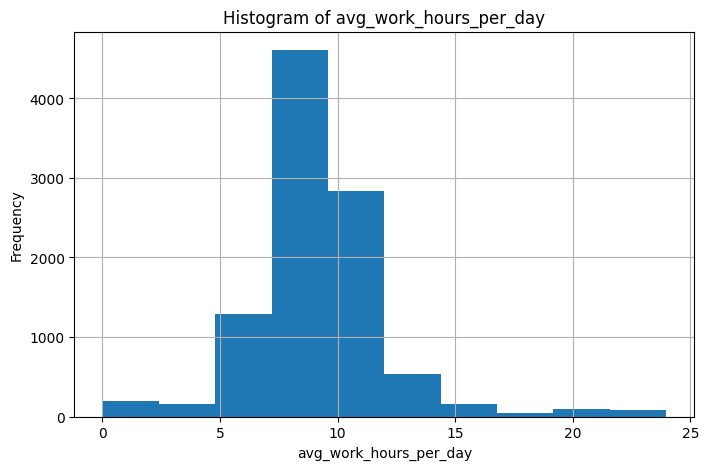

In [ ]:
plt.figure(figsize=(8,5))

plt.hist(df["avg_work_hours_per_day"], bins=10)
plt.title("Histogram of avg_work_hours_per_day")
plt.xlabel("avg_work_hours_per_day")
plt.ylabel("Frequency")
plt.grid()
plt.show()

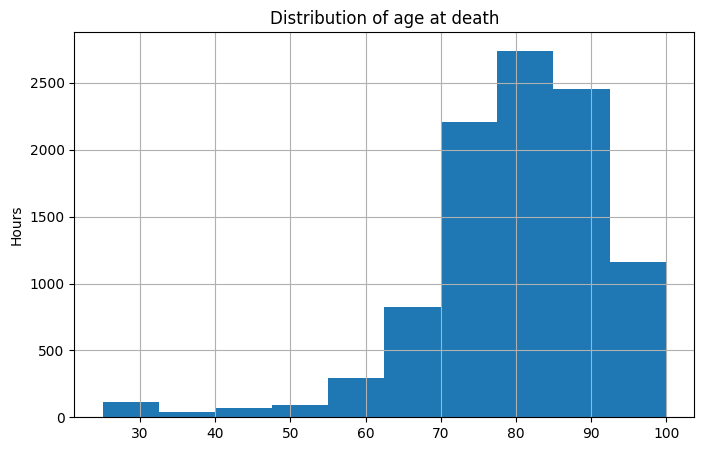

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["age_at_death"])
plt.title("Distribution of age at death")
plt.ylabel("Hours")
plt.grid()
plt.show()

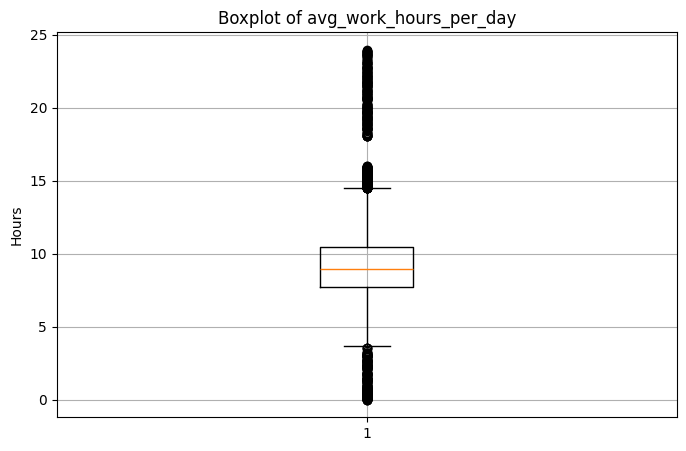

In [ ]:
plt.figure(figsize=(8,5))
plt.boxplot(df["avg_work_hours_per_day"])
plt.title("Boxplot of avg_work_hours_per_day")
plt.ylabel("Hours")
plt.grid()
plt.show()

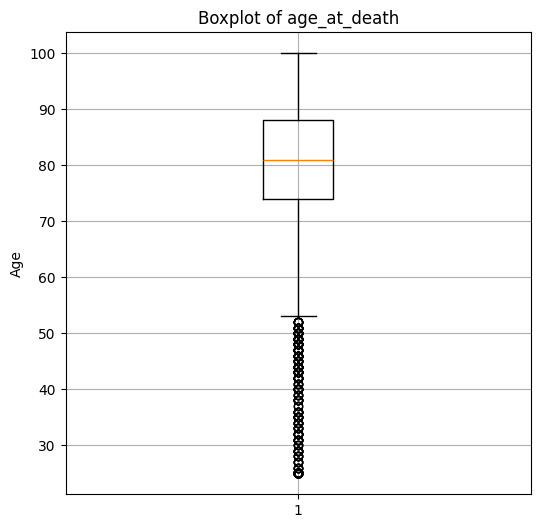

In [ ]:
plt.figure(figsize=(6,6))
plt.boxplot(df["age_at_death"])
plt.title("Boxplot of age_at_death")
plt.ylabel("Age")
plt.grid()
plt.show()


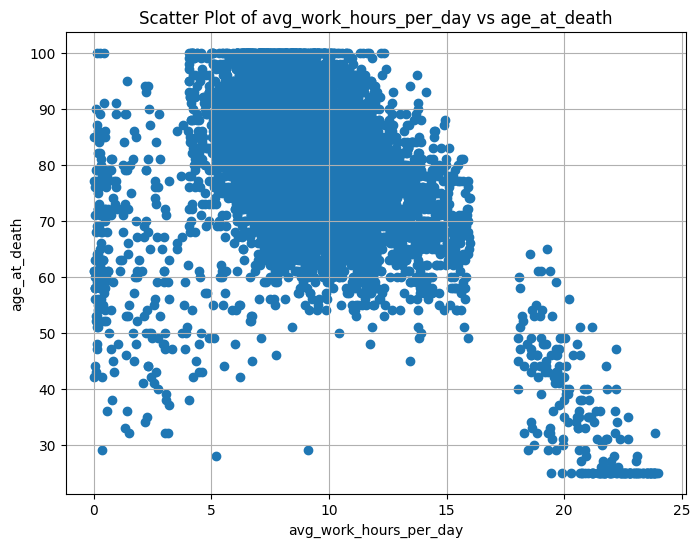

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(
    df["avg_work_hours_per_day"],
    df["age_at_death"],
    marker="o"

)
plt.title("Scatter Plot of avg_work_hours_per_day vs age_at_death")
plt.xlabel("avg_work_hours_per_day")
plt.ylabel("age_at_death")
plt.grid()
plt.show()

Correlation Matrix

In [ ]:
correlation = df.corr(numeric_only=True)
print(correlation)

                                  id  avg_work_hours_per_day  \
id                          1.000000               -0.017117   
avg_work_hours_per_day     -0.017117                1.000000   
avg_rest_hours_per_day      0.015986               -0.685748   
avg_sleep_hours_per_day     0.001300               -0.289157   
avg_exercise_hours_per_day -0.003653               -0.107078   
age_at_death                0.013897               -0.428623   

                            avg_rest_hours_per_day  avg_sleep_hours_per_day  \
id                                        0.015986                 0.001300   
avg_work_hours_per_day                   -0.685748                -0.289157   
avg_rest_hours_per_day                    1.000000                -0.436039   
avg_sleep_hours_per_day                  -0.436039                 1.000000   
avg_exercise_hours_per_day               -0.203204                -0.001596   
age_at_death                              0.305016                 0.005955  

HeatMap

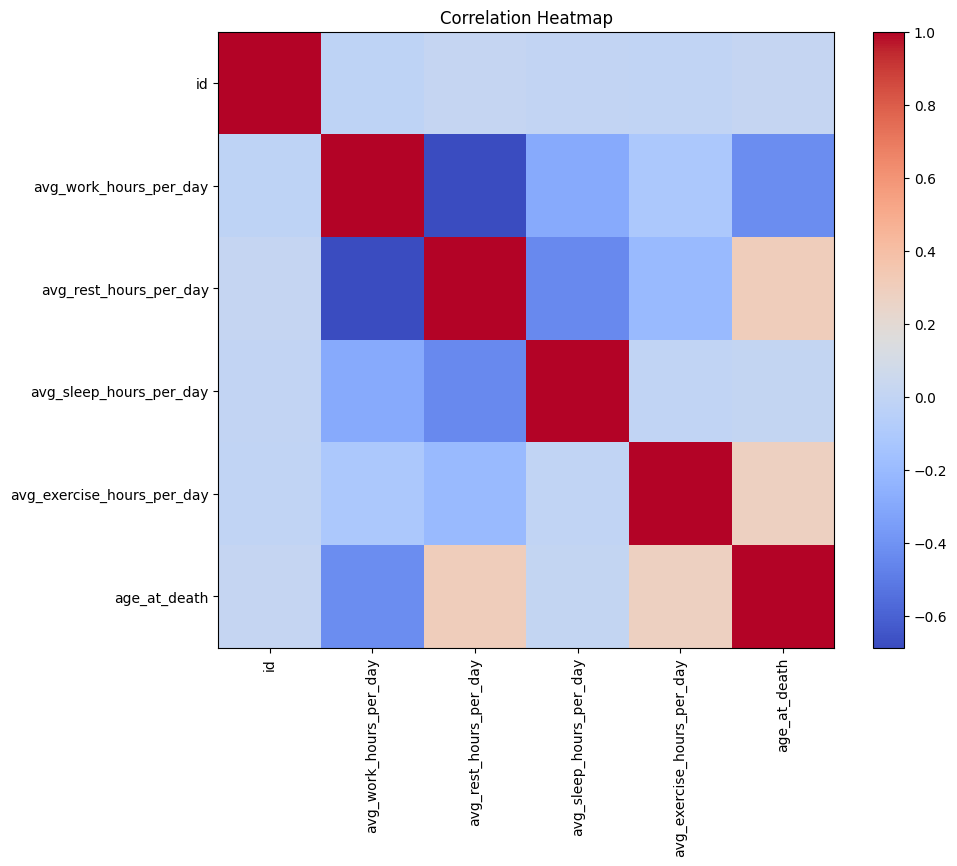

In [ ]:
plt.figure(figsize=(10,8))
plt.imshow(correlation, cmap="coolwarm",)
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Independent Variable(Feature)

X = df[["avg_work_hours_per_day"]]

# Dependent Variable(Target)

y = df["age_at_death"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 1)
X_test shape: (2000, 1)
y_train shape: (8000,)
y_test shape: (2000,)


In [ ]:
model = PolynomialFeatures(degree=2)
X_train_poly = model.fit_transform(X_train)
X_test_poly = model.transform(X_test)

Fit_Trasnform()

In [ ]:
y_pred = model.predict(X_test_poly)
print(y_pred)

AttributeError: 'PolynomialFeatures' object has no attribute 'predict'